# 03 · Forecasting the premium (Tier 2)

**Owner: Nahid**

Forecast next-month realized variance with HAR-RV, using only information available at each day's close. Then the **forecast premium** = VIX²/10000 − forecast tells you, in real time, whether the premium looks worth collecting.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import load_daily, EPISODES, episode_mask
df = load_daily('../data/daily.csv')
df.tail()

,spx_open,spx_high,spx_low,spx_close,vix,vix3m,rf,logret,iv_var,rv_d,rv_w,rv_m,rv_parkinson_d,rv_fwd21,vrp,vrp_volpts,vix_ratio
date,,,,,,,,,,,,,,,,,
2026-10-27,7699.470215,7736.240234,7677.160156,7722.600098,17.520000,19.570000,0.0405,0.005952,0.030695,0.008928,0.014701,0.009330,0.005342,NaN,NaN,NaN,0.895248
2026-10-28,7735.560059,7758.430176,7718.370117,7743.979980,16.910000,19.219999,0.0401,0.002765,0.028595,0.001926,0.013411,0.009388,0.002436,NaN,NaN,NaN,0.879813
2026-10-29,7699.609863,7732.209961,7690.939941,7720.390137,17.200001,19.370001,0.0400,-0.003051,0.029584,0.002346,0.006430,0.009423,0.002603,NaN,NaN,NaN,0.887971
2026-10-30,7631.069824,7637.479980,7527.560059,7580.069824,19.420000,20.780001,0.0399,-0.018342,0.037714,0.084785,0.022024,0.013415,0.019101,NaN,NaN,NaN,0.934552
2026-11-02,7610.830078,7662.229980,7539.379883,7541.399902,21.150000,21.600000,0.0403,-0.005115,0.044732,0.006592,0.020915,0.013088,0.023745,NaN,NaN,NaN,0.979167


## 1. HAR model
`rv_fwd21 ~ 1 + rv_d + rv_w + rv_m` (inputs already in `daily.csv`).

Fit on an **expanding window**: on the first trading day of each month, fit on all rows whose target is already known (the target needs 21 future days, so only use rows up to 22 trading days before that date), then predict for every day of that month. Start forecasting in 2007 so the first fit has 2 years of data.

In [2]:
import statsmodels.api as sm
feats = ['rv_d', 'rv_w', 'rv_m']
month_starts = df.index.to_series().groupby(df.index.to_period('M')).first()
month_starts = month_starts[month_starts >= '2007-01-01']
starts = [df.index.get_loc(ms) for ms in month_starts] + [len(df)]

df['har_fcst'] = np.nan
coefs = {}
for ms, pos, nxt in zip(month_starts, starts[:-1], starts[1:]):
    # train only on rows whose 21-day target was already known on this date
    train = df.iloc[:pos - 21].dropna(subset=feats + ['rv_fwd21'])
    fit = sm.OLS(train['rv_fwd21'], sm.add_constant(train[feats])).fit()
    coefs[ms] = fit.params
    X = sm.add_constant(df.iloc[pos:nxt][feats], has_constant='add')
    df.loc[df.index[pos:nxt], 'har_fcst'] = fit.predict(X)   # forecast this month

coefs = pd.DataFrame(coefs).T
display(coefs.iloc[[0, -1]].round(3))
print(f"forecast days: {df['har_fcst'].notna().sum()}, forecasts <= 0: {(df['har_fcst'] <= 0).sum()}")

,const,rv_d,rv_w,rv_m
2007-01-03,0.007,-0.002,0.170,0.121
2026-11-02,0.016,0.048,0.298,0.207


forecast days: 4990, forecasts <= 0: 0


## 2. Forecast accuracy
Compare `har_fcst` with two baselines: `rv_m` (last month's realized variance) and `iv_var` (VIX² itself).

Losses: MSE, and QLIKE = RV/F − log(RV/F) − 1 (Patton 2011; it is robust to noise in the RV proxy). VIX² should look biased upward, and that bias is the premium.

In [3]:
ev = df[['rv_fwd21', 'har_fcst', 'rv_m', 'iv_var']].dropna()
rv = ev['rv_fwd21']
acc = {}
for name, col in [('HAR', 'har_fcst'), ('Last month RV', 'rv_m'), ('VIX²', 'iv_var')]:
    f = ev[col].clip(lower=1e-4)
    acc[name] = {'mean bias (fcst - RV)': (f - rv).mean(),
                 'MSE x 10^4': 1e4 * ((rv - f) ** 2).mean(),
                 'QLIKE': (rv / f - np.log(rv / f) - 1).mean()}
print(f"evaluation: {len(ev)} days, {ev.index[0].date()} to {ev.index[-1].date()}")
display(pd.DataFrame(acc).T.round(4))

evaluation: 4969 days, 2007-01-03 to 2026-10-02


,mean bias (fcst - RV),MSE x 10^4,QLIKE
HAR,0.0023,57.9463,0.3897
Last month RV,-0.0000,65.6063,0.5687
VIX²,0.0078,44.7738,0.3671


## 3. Forecast premium and the trading rule
`df['fcst_vrp'] = df['iv_var'] - df['har_fcst']`

**Before running anything on 2016 onwards, write the rule in the README and commit it.** The commit timestamp is your proof that the rule was fixed in advance. Example rule:

> Hold a short variance position on day t only if yesterday's `fcst_vrp` > 0 and yesterday's `vix_ratio` < 1.

Use 2008–2015 for any choices. Run the rule **once** on 2016 onwards.

In [4]:
df['fcst_vrp'] = df['iv_var'] - df['har_fcst']
df['signal'] = (df['fcst_vrp'].shift(1) > 0) & (df['vix_ratio'].shift(1) < 1)
for label, part in [('train 2008-2015', df.loc['2008':'2015']), ('test 2016+', df.loc['2016':])]:
    print(f"{label}: signal on {part['signal'].mean():.1%} of days | "
          f"forecast premium > 0: {(part['fcst_vrp'] > 0).mean():.1%} | "
          f"VIX curve inverted: {(part['vix_ratio'] >= 1).mean():.1%}")

train 2008-2015: signal on 58.3% of days | forecast premium > 0: 68.1% | VIX curve inverted: 13.7%
test 2016+: signal on 62.6% of days | forecast premium > 0: 67.5% | VIX curve inverted: 7.4%


## 4. Rule vs always-short, test period
Compare on non-overlapping months: mean P&L, CVaR, worst month, P&L in each episode. Say plainly that only a few tail events are in the test period.

train 2008-2015: rule minus always-short = 0.0012 per month, paired t = 0.17
test 2016+: rule minus always-short = 0.0004 per month, paired t = 0.09


months    mean     std  Sharpe (ann.)  5% CVaR  \
train 2008-2015 always short    96.0  0.0087  0.0768         0.3917  -0.2313   
                rule            96.0  0.0099  0.0323         1.0607  -0.0551   
test 2016+      always short   129.0  0.0073  0.0584         0.4350  -0.1457   
                rule           129.0  0.0078  0.0150         1.7920  -0.0225   

                              worst month  months in market  
train 2008-2015 always short      -0.5261               NaN  
                rule              -0.2466            0.6042  
test 2016+      always short      -0.5418               NaN  
                rule              -0.0363            0.5581

,signal on day 1,days signal on,always short (var),rule (var)
GFC 2008,True,0.226,-0.247,-0.247
US downgrade Aug 2011,False,0.135,-0.180,0.000
China deval Aug 2015,False,0.188,-0.080,0.000
Volmageddon Feb 2018,False,0.227,-0.048,0.000
COVID Mar 2020,True,0.137,-0.722,-0.722
2022 bear (contrast),True,0.847,-0.007,-0.007
Yen carry Aug 2024,False,0.174,-0.010,0.000
Tariff shock Apr 2025,False,0.125,-0.180,0.000


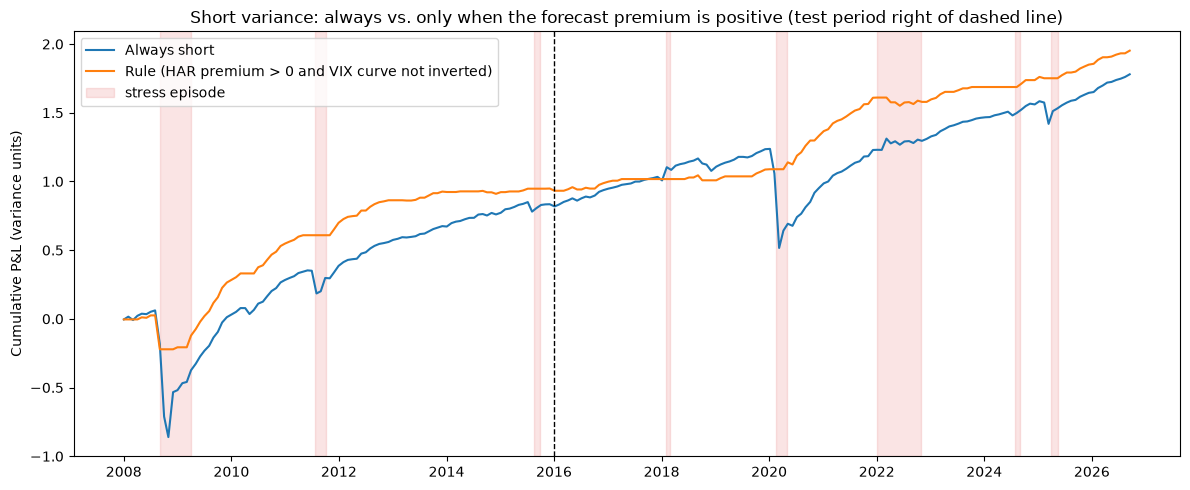

In [6]:
from scipy import stats
m = df.loc['2008':].dropna(subset=['vrp']).iloc[::21][['vrp', 'signal']].copy()
m['rule'] = m['vrp'].where(m['signal'], 0.0)     # cash (P&L 0) when the signal is off

def summarize(x):
    k = max(1, int(np.ceil(0.05 * len(x))))      # worst 5% of months
    return {'months': len(x), 'mean': x.mean(), 'std': x.std(),
            'Sharpe (ann.)': np.sqrt(12) * x.mean() / x.std(),
            '5% CVaR': x.nsmallest(k).mean(), 'worst month': x.min()}

rows = {}
for label, part in [('train 2008-2015', m.loc[:'2015']), ('test 2016+', m.loc['2016':])]:
    rows[(label, 'always short')] = summarize(part['vrp'])
    rows[(label, 'rule')] = summarize(part['rule']) | {'months in market': part['signal'].mean()}
    d = part['rule'] - part['vrp']
    print(f"{label}: rule minus always-short = {d.mean():.4f} per month, paired t = {stats.ttest_1samp(d, 0).statistic:.2f}")
display(pd.DataFrame(rows).T.round(4))

ep = {}   # what the rule did on day 1 of each stress episode
for name in EPISODES:
    sub = df[episode_mask(df.index, name)]
    on = bool(sub['signal'].iloc[0])
    ep[name] = {'signal on day 1': on, 'days signal on': sub['signal'].mean(),
                'always short (var)': sub['vrp'].iloc[0], 'rule (var)': sub['vrp'].iloc[0] if on else 0.0}
display(pd.DataFrame(ep).T.infer_objects().round(3))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(m.index, m['vrp'].cumsum(), label='Always short')
ax.plot(m.index, m['rule'].cumsum(), label='Rule (HAR premium > 0 and VIX curve not inverted)')
ax.axvline(pd.Timestamp('2016-01-01'), color='k', ls='--', lw=1)
for i, (name, (s, e)) in enumerate(EPISODES.items()):
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color='tab:red', alpha=0.12, label='stress episode' if i == 0 else None)
ax.set_ylabel('Cumulative P&L (variance units)')
ax.set_title('Short variance: always vs. only when the forecast premium is positive (test period right of dashed line)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../docs/figures/fig3_rule_vs_always_short.png', dpi=150)
plt.show()

In [7]:
test = df.loc['2016':].dropna(subset=['vrp'])
rob = []
for k in range(21):          # every possible trading day in the month
    mk = test.iloc[k::21]
    rule = mk['vrp'].where(mk['signal'], 0.0)
    rob.append({'always: worst month': mk['vrp'].min(), 'rule: worst month': rule.min(),
                'always: Sharpe': np.sqrt(12) * mk['vrp'].mean() / mk['vrp'].std(),
                'rule: Sharpe': np.sqrt(12) * rule.mean() / rule.std()})
display(pd.DataFrame(rob).describe().loc[['min', '50%', 'max']].round(3))

,always: worst month,rule: worst month,always: Sharpe,rule: Sharpe
min,-0.816,-0.795,0.286,0.038
50%,-0.728,-0.177,0.358,1.197
max,-0.355,-0.036,0.775,2.222


Robustness: across all 21 possible trading days, the rule’s median worst month is −0.18 vs −0.73 for always-short, and its median Sharpe is 1.2 vs 0.36. On the unluckiest day the rule still loses 0.80 in COVID, because the signal was on when the crash began from calm markets. The rule reduces risk on average but does not protect against a crash that starts from calm conditions.

## 5. Save the signal for notebook 04
Add `har_fcst`, `fcst_vrp` and `signal` to `data/daily.csv`, so the straddle backtest in notebook 04 can trade only when the signal is on.

In [8]:
df.to_csv('../data/daily.csv')
print(pd.read_csv('../data/daily.csv', nrows=1).columns[-3:].tolist())

['har_fcst', 'fcst_vrp', 'signal']
